# 31 · 에너지 기반 모델과 MCMC

📎 **이번 질문** · 과일 측정값이 자주 나오는 위치를 낮은 에너지로 표현하면, 확률을 계산하고 새 과일을 뽑을 수 있을까요?

이 노트북은 1차원 과일 측정 좌표를 사용합니다. 작은 상태표에서 정규화 상수를 손으로 더한 뒤, 두 봉우리를 표현하는 에너지 모형을 실제 학습합니다. 마지막에는 같은 학습 모형을 Langevin chain으로 샘플링합니다.

- 준비물: [12 확률·Gaussian](../02_연결/12_gaussian_information.ipynb), [27 표본 추정](27_monte_carlo_gradients.ipynb), [01 미분](../00_기초/01_gradients_and_learning.ipynb).
- 범위: NumPy float64·CPU, 2개 파라미터의 에너지 모형. 신경망 EBM이나 이미지 생성 전체를 재현하지 않습니다.
- 구조는 에너지 함수, 학습 목적은 관측 NLL, 갱신은 경사하강, 학습 뒤 사용은 밀도 계산 또는 MCMC입니다.

> **용어** · **에너지 기반 모델(EBM)**은 낮은 에너지에 큰 확률을 주는 모형입니다. **정규화 상수 Z**는 모든 가중치를 더하거나 적분한 값입니다. **MCMC**는 앞 표본에서 다음 표본으로 움직이는 Markov chain을 이용해 목표 분포의 표본을 얻는 방법입니다.

| 표시 | 읽는 방법 |
|---|---|
| 🔑 핵심 | 수식·shape·구현을 연결합니다 |
| 🔍 확인 | 그림과 실제 계산을 해석합니다 |
| 📎 참고 | 용어·코드·범위를 읽습니다 |
| ✏️ 연습 | 핵심 한두 줄을 채워 검산합니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. 에너지의 절댓값보다 상대 차이가 중요하며 확률에는 Z가 필요합니다.
2. NLL 기울기는 자료와 모형의 특징 평균 차이입니다. 모형 기대값 추정 오류도 학습 기울기에 들어갑니다.
3. Langevin의 작은 스텝과 MALA의 수락 보정은 서로 다른 역할입니다. chain 표본을 독립 표본으로 세지 않습니다.

[학습 경로](../../docs/CURRICULUM.md) · [그림 보조 코드](../../src/utils/energy_plots.py)

In [1]:
# 준비 셀: 실행 위치와 무관하게 프로젝트를 찾습니다.
import sys
from pathlib import Path
project_root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0,str(project_root))
import numpy as np
from src.utils import setup_plots,run_check
from src.utils.gradcheck import numerical_gradient
from src.utils.energy_plots import (plot_energy_table,plot_phase_terms,plot_training_plan,
    plot_energy_fit,plot_langevin_proposal,plot_dependent_blocks,plot_chains,plot_chain_density)
setup_plots()
print('NumPy',np.__version__,'· 에너지와 chain 준비 완료')

NumPy 2.4.6 · 에너지와 chain 준비 완료


## 🔑 1. 낮은 에너지의 상태에 더 큰 확률을 줍니다

**이 절에서 가져갈 것:** 에너지를 exp(−E)로 바꾸고 전체 합으로 나누면 상태 확률이 됩니다.

과일이 세 바구니 중 어디에서 나올지 점수표로 나타냅니다. 에너지가 $0,\log2,\log4$라면 가중치는 $1,1/2,1/4$이고 합은 $7/4$입니다.

$$p_j=\frac{e^{-E_j}}{Z},\quad Z=\sum_k e^{-E_k},\qquad p=(4/7,2/7,1/7).$$

에너지와 확률은 `(K,)`, Z는 scalar입니다. 모든 에너지에 같은 c를 더하면 분자·분모가 함께 $e^{-c}$배 되어 확률은 그대로입니다. `exp` 넘침을 막으려면 log 가중치의 최댓값을 빼고 계산합니다.

> **용어** · **상태**는 가능한 결과 하나입니다. **partition function**은 Z의 다른 이름입니다. **log-sum-exp**는 지수합의 로그를 안정적으로 계산하는 방법입니다.
>
> **코드** · `np.asarray`는 입력을 배열로, `np.exp`는 각 원소를 지수로 바꿉니다. `.sum()`은 상태 축을 합합니다. `a[None,:]`는 그림을 위해 행 축을 추가합니다.

In [2]:
energy_three=np.log(np.array([1.,2.,4.]))
weights_three=np.exp(-energy_three)
masses_three=weights_three/weights_three.sum()
print('손계산 Z:',1+.5+.25,'· 확률:',[4/7,2/7,1/7])

손계산 Z: 1.75 · 확률: [0.5714285714285714, 0.2857142857142857, 0.14285714285714285]


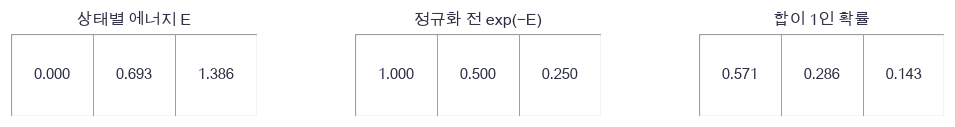

In [3]:
plot_energy_table(energy_three,weights_three,masses_three)

🔍 **확인** · 에너지는 확률이 아닙니다. 가운데 가중치의 합은 1이 아니지만 오른쪽 확률의 합은 1입니다. 에너지가 낮은 첫 바구니가 가장 자주 선택됩니다.

In [4]:
def normalize_energy(values):
    """유한 상태 에너지를 안정적인 logZ와 확률로 바꿉니다. (K,) → scalar,(K,)."""
    logits=-np.asarray(values,dtype=float)
    top=logits.max()
    weights=np.exp(logits-top)
    return top+np.log(weights.sum()),weights/weights.sum()

In [5]:
# 쓰는 것: energy_three, masses_three (1절 그림)
loop_weights=[]
for value in energy_three:
    loop_weights.append(np.exp(-value))
loop_mass=np.array(loop_weights)/sum(loop_weights)
logZ_three,vector_mass=normalize_energy(energy_three)
np.testing.assert_allclose(vector_mass,[4/7,2/7,1/7])  # 검산: 손계산과 벡터화
np.testing.assert_allclose(loop_mass,vector_mass)  # 검산: 반복문과 벡터화
np.testing.assert_allclose(normalize_energy(energy_three+10000)[1],masses_three)  # 검산: 공통 이동 불변
assert np.isclose(vector_mass.sum(),1.), '상태 확률 합은 1이어야 합니다'
print('손계산·반복문·벡터화·에너지 이동 검산 통과')

손계산·반복문·벡터화·에너지 이동 검산 통과


### ✏️ 연습 1 · 에너지의 공통 이동

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

모든 에너지에 c를 더했을 때 새 logZ를 쓰세요.

In [6]:
def exercise_shift(logZ,c):
    """에너지의 공통 이동의 핵심 계산입니다."""
    ### 구현할 내용: 모든 에너지에 c를 더했을 때 새 logZ를 쓰세요.
    raise NotImplementedError
    return new_logZ

In [7]:
def check_shift(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    assert np.isclose(candidate(2.,3.),-1.), 'logZ는 c만큼 줄어야 합니다'
    print("연습 1 통과")

run_check(check_shift,exercise_shift,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_shift: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
new_logZ=logZ-c
```

</details>

## 🔑 2. 자료와 모형의 평균을 서로 당깁니다

**이 절에서 가져갈 것:** 정규화 상수의 미분을 포함하면 NLL 기울기는 두 특징 평균의 차이입니다.

한 줄의 과일 측정값에서 두 봉우리를 허용하려고
$E_\theta(x)=x^4/4+\theta_0x+\theta_1x^2$를 사용합니다. 양의 4차 항 덕분에 어떤 유한 θ에서도 무한 공간의 적분이 유한합니다.

$$\phi(x)=(x,x^2),\quad \nabla_\theta E=\phi(x),\quad E'(x)=x^3+\theta_0+2\theta_1x.$$
$$L=\frac1N\sum_iE(x_i)+\log Z,\quad \nabla_\theta\log Z=-\mathbb E_{p_\theta}\phi(x),\quad
\nabla_\theta L=\underbrace{\overline\phi_{data}}_{positive\ phase}-\underbrace{\mathbb E_{p_\theta}\phi}_{negative\ phase}.$$

θ는 `(2,)`, 관측 x는 `(N,)`, 특징 행렬은 `(N,2)`입니다. 경사하강은 자료가 있는 곳의 에너지를 내리는 방향과 모형이 이미 많이 놓인 곳의 에너지를 올리는 방향을 함께 사용합니다.

계산 기준은 $[-4,4]$의 **균일한 중점 격자**입니다. 폭 Δ에서 $Z\approx\Delta\sum_j e^{-E(x_j)}$, density는 $e^{-E}/Z$, 격자 질량은 density×Δ입니다. 격자 모형의 합은 정확히 1이지만 연속 적분에는 영역 절단·격자 오차가 남습니다.

> **용어** · **positive/negative phase**는 자료 기대값과 모형 기대값의 두 항을 부르는 이름입니다. **밀도**와 한 칸의 **질량**은 Δ만큼 다릅니다. 학습에서는 density NLL을 관측 수로 평균냅니다.
>
> **코드** · `np.column_stack([x,x**2])`는 특징 두 열을 붙입니다. `mass @ features`는 상태별 확률로 특징을 가중 평균합니다.

In [8]:
phase_edges=np.linspace(-4,4,802)
phase_grid=(phase_edges[:-1]+phase_edges[1:])/2
phase_theta=np.array([.2,-.8])
phase_logits=-(.25*phase_grid**4+phase_theta[0]*phase_grid+phase_theta[1]*phase_grid**2)
phase_mass=np.exp(phase_logits-phase_logits.max())
phase_mass/=phase_mass.sum()
phase_density=phase_mass/(phase_grid[1]-phase_grid[0])
phase_data=np.array([-1.,0.,1.,1.])
phase_positive=np.array([phase_data.mean(),np.mean(phase_data**2)])
phase_negative=phase_mass@np.column_stack([phase_grid,phase_grid**2])
phase_gradient=phase_positive-phase_negative

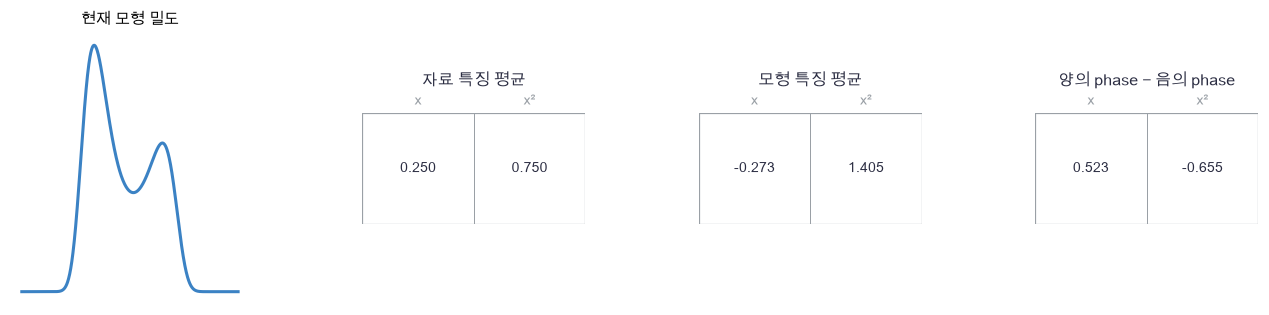

In [9]:
plot_phase_terms(phase_grid,phase_density,phase_positive,phase_negative,phase_gradient)

🔍 **확인** · 두 특징은 x의 평균과 제곱 평균입니다. 한 항만 미분하면 확률을 다른 위치에서 가져와야 한다는 정규화 효과가 빠집니다. 그림의 차이는 아래 실제 NLL 미분과 대조합니다.

In [10]:
def energy(x,theta):
    """E=x⁴/4+theta[0]x+theta[1]x². x:(N,), theta:(2,) → (N,)."""
    return .25*x**4+theta[0]*x+theta[1]*x**2

In [11]:
def energy_slope(x,theta):
    """입력 미분 dE/dx=x³+theta[0]+2theta[1]x. → x와 같은 shape."""
    return x**3+theta[0]+2*theta[1]*x

In [12]:
def energy_features(x):
    """파라미터 미분 ∂E/∂theta=(x,x²)를 행에 모읍니다. (N,) → (N,2)."""
    return np.column_stack([x,x**2])

In [13]:
def grid_distribution(grid,theta):
    """같은 폭의 중점 격자로 Z를 근사합니다. → logZ, density:(K,), mass:(K,)."""
    # 쓰는 것: energy (2절)
    width=grid[1]-grid[0]
    logits=-energy(grid,theta)
    top=logits.max()
    weights=np.exp(logits-top)
    masses=weights/weights.sum()
    logZ=top+np.log(weights.sum())+np.log(width)
    return logZ,masses/width,masses

In [14]:
def nll_gradient(data,grid,theta):
    """격자 근사 평균 density NLL과 두 phase의 차이를 반환합니다. → scalar,(2,)."""
    # 쓰는 것: energy, energy_features, grid_distribution (2절)
    logZ,_,mass=grid_distribution(grid,theta)
    positive=energy_features(data).mean(axis=0)
    negative=mass@energy_features(grid)
    return float(energy(data,theta).mean()+logZ),positive-negative

In [15]:
def check_energy_derivatives():
    """동일 격자의 모든 θ와 입력 미분, Hessian의 공분산 식을 검산합니다."""
    # 쓰는 것: phase_grid, phase_theta, phase_data, phase_gradient (2절 그림) · energy,energy_slope (2절) · numerical_gradient (준비 셀)
    theta=phase_theta.copy()
    loss,gradient=nll_gradient(phase_data,phase_grid,theta)
    def objective():
        """잡음 없이 같은 관측·격자에서 현재 NLL을 계산합니다."""
        return nll_gradient(phase_data,phase_grid,theta)[0]
    numeric=numerical_gradient(objective,theta)
    np.testing.assert_allclose(gradient,numeric,atol=1e-8)  # 검산: logZ를 포함한 θ 미분
    np.testing.assert_allclose(gradient,phase_gradient)  # 검산: 그림의 두 phase
    x=np.array([-.7,.2,1.1])
    def total_energy():
        """입력 원소별 차분을 위한 에너지 합입니다."""
        return energy(x,theta).sum()
    np.testing.assert_allclose(energy_slope(x,theta),numerical_gradient(total_energy,x),atol=1e-8)  # 검산: 입력 미분
    mass=grid_distribution(phase_grid,theta)[2]
    features=energy_features(phase_grid)
    centered=features-mass@features
    covariance=centered.T@(mass[:,None]*centered)
    # 1. 각 파라미터 방향으로 기울기를 차분해 Hessian의 열을 만듭니다.
    numeric_hessian=np.zeros((2,2))
    for column in range(2):
        offset=np.zeros(2)
        offset[column]=1e-5
        plus=nll_gradient(phase_data,phase_grid,theta+offset)[1]
        minus=nll_gradient(phase_data,phase_grid,theta-offset)[1]
        numeric_hessian[:,column]=(plus-minus)/2e-5
    np.testing.assert_allclose(covariance,numeric_hessian,atol=1e-8)  # 검산: logZ Hessian = 모형 특징 공분산
    assert np.linalg.eigvalsh(covariance).min()>-1e-12, '격자 logZ의 Hessian은 공분산이므로 PSD여야 합니다'
    return float(np.max(np.abs(gradient-numeric)))

In [16]:
print("전체 θ·입력 미분 및 공분산 검산:",check_energy_derivatives())

전체 θ·입력 미분 및 공분산 검산: 3.3676483823796843e-10


### ✏️ 연습 2 · 두 phase의 차이

자료 평균과 모형 평균으로 NLL 기울기를 쓰세요.

In [17]:
def exercise_phases(positive,negative):
    """두 phase의 차이의 핵심 계산입니다."""
    ### 구현할 내용: 자료 평균과 모형 평균으로 NLL 기울기를 쓰세요.
    raise NotImplementedError
    return gradient

In [18]:
def check_phases(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    np.testing.assert_allclose(candidate(np.array([1.,2.]),np.array([.5,3.])),[.5,-1.])  # 검산: 자료-모형
    print("연습 2 통과")

run_check(check_phases,exercise_phases,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_phases: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
gradient=positive-negative
```

</details>

## 🔑 3. 정규화된 우도로 에너지 모형을 실제 학습합니다

**이 절에서 가져갈 것:** 학습·평가 자료를 나누고 같은 격자의 NLL로 두 파라미터를 갱신합니다.

두 종류 과일이 많이 측정되는 분포를 만들겠습니다. 자료 생성 θ=(.35,−1.5)의 격자 질량에서 관측을 독립 추출합니다. 학습 함수에는 관측과 격자만 주고 이 정답 θ를 주지 않습니다. 자료가 격자에 놓인 것은 실험용 이산화이며, 밀도 NLL은 격자 확률 NLL에서 log Δ를 더한 값입니다.

**고정 계획:** train512(seed311), validation256(seed312), test512(seed313), θ=(0,0)에서 경사하강300회·학습률.08. validation은 기록만 하고 마지막 θ를 사용합니다. test를 보고 예산을 고르지 않습니다.

$$\theta_{t+1}=\theta_t-.08\nabla_\theta L.$$

이 작은 모형은 negative phase를 격자 합으로 계산합니다. 고차원 EBM에서는 이 합이 어려워 MCMC 등으로 근사한다는 연결을 다음 절에서 확인합니다. 여기의 학습은 MCMC 근사 학습이 아닙니다.

> **용어** · **heldout**은 갱신에 쓰지 않은 자료입니다. **경사하강**은 현재 목적의 기울기 반대 방향으로 파라미터를 움직이는 갱신 규칙입니다.
>
> **코드** · `rng.choice(grid,count,p=mass)`는 주어진 질량에 비례해 격자 위치를 뽑습니다. `.copy()`는 초기값과 학습 배열을 분리합니다.

In [19]:
# 쓰는 것: phase_grid (2절) · grid_distribution (2절)
grid=phase_grid.copy()
true_theta=np.array([.35,-1.5])
true_logZ,true_density,true_mass=grid_distribution(grid,true_theta)
train=np.random.default_rng(311).choice(grid,512,p=true_mass)
validation=np.random.default_rng(312).choice(grid,256,p=true_mass)
test=np.random.default_rng(313).choice(grid,512,p=true_mass)
training_settings=np.array([len(train),len(validation),len(test),300])

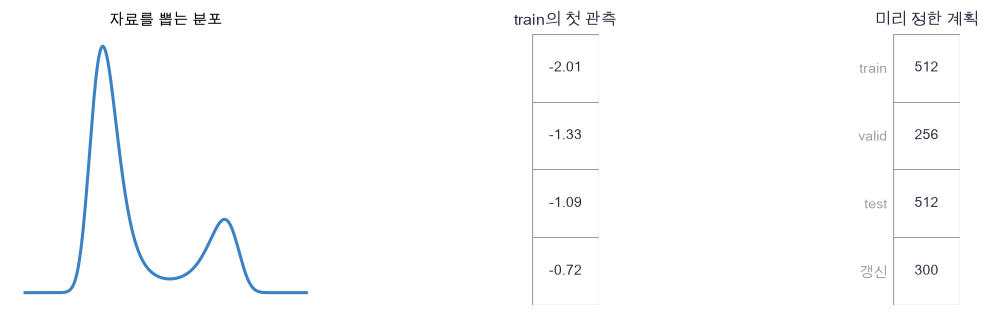

In [20]:
plot_training_plan(grid,true_density,train[:4],training_settings)

🔍 **확인** · 낮은 에너지 주변에 자료가 모입니다. 관측 수와 갱신 수는 그림의 계획대로 고정합니다. 확률을 계산하는 구조·NLL 목적·갱신 규칙을 따로 짚어 보세요.

In [21]:
def fit_energy(train,validation,grid,initial,steps=300,rate=.08):
    """정확한 격자 합의 기울기로 두 파라미터를 학습합니다. → theta, history:(T,3)."""
    # 쓰는 것: nll_gradient (2절)
    theta=initial.copy()
    history=[]
    for step in range(steps+1):
        train_loss,gradient=nll_gradient(train,grid,theta)
        if step%20==0:
            valid_loss,_=nll_gradient(validation,grid,theta)
            history.append([step,train_loss,valid_loss])
        if step<steps:
            theta-=rate*gradient
    return theta,np.asarray(history)

In [22]:
# 쓰는 것: grid_distribution,nll_gradient (2절) · train,validation,grid,true_theta,test (3절)
initial_theta=np.zeros(2)
learned_theta,history=fit_energy(train,validation,grid,initial_theta)
initial_density=grid_distribution(grid,initial_theta)[1]
learned_density=grid_distribution(grid,learned_theta)[1]
assert np.all(initial_theta==0), '학습이 초기 기준 배열을 바꾸지 않아야 합니다'
assert history[-1,1]<history[0,1], '이 고정 예제에서 train NLL이 줄어야 합니다'
print('학습 θ:',learned_theta)
print('test density NLL · 초기/학습/자료생성 모형:',[nll_gradient(test,grid,p)[0] for p in [initial_theta,learned_theta,true_theta]])

학습 θ: [ 0.35777255 -1.51154969]
test density NLL · 초기/학습/자료생성 모형: [3.1802576460263765, 1.296373187027048, 1.2944290186745775]


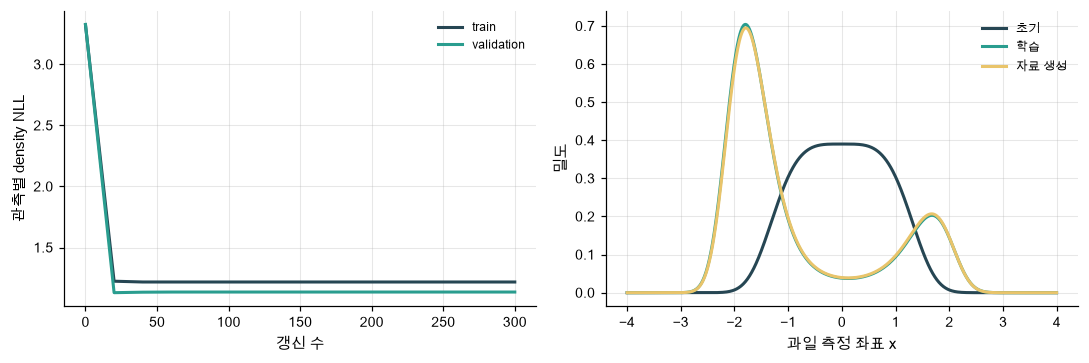

In [23]:
plot_energy_fit(history,grid,[initial_density,learned_density,true_density],['초기','학습','자료 생성'])

🔍 **확인** · 자료 생성 모형의 점수는 정답 분포를 아는 합성 실험의 참고값입니다. 유한 test에서는 그 값이 언제나 가장 작다는 부등식을 주장하지 않습니다. θ를 알아냈는지와 새 관측의 NLL을 구분합니다.

In [24]:
# 쓰는 것: learned_theta,grid (3절) · grid_distribution (2절)
normalization_checks=[]
for radius,count in [(4.,801),(4.,1602),(6.,2403)]:
    edges=np.linspace(-radius,radius,count+1)
    centers=(edges[:-1]+edges[1:])/2
    logZ,density,mass=grid_distribution(centers,learned_theta)
    np.testing.assert_allclose(mass.sum(),1.)  # 검산: 이산 질량의 정규화
    normalization_checks.append(logZ)
np.testing.assert_allclose(normalization_checks,normalization_checks[-1],atol=1e-6)  # 검산: 이 설정에서 격자·영역 오차가 작음
print('반경/해상도를 바꾼 logZ:',normalization_checks)

반경/해상도를 바꾼 logZ: [np.float64(3.2680361852564497), np.float64(3.268036185256448), np.float64(3.2680361852562703)]


### ✏️ 연습 3 · 평균 NLL의 두 항

관측별 에너지 평균에 logZ를 더하세요.

In [25]:
def exercise_nll(observed_energy,logZ):
    """평균 NLL의 두 항의 핵심 계산입니다."""
    ### 구현할 내용: 관측별 에너지 평균에 logZ를 더하세요.
    raise NotImplementedError
    return loss

In [26]:
def check_nll(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    assert np.isclose(candidate(np.array([1.,3.]),.5),2.5), '평균2에 .5를 더해야 합니다'
    print("연습 3 통과")

run_check(check_nll,exercise_nll,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_nll: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
loss=observed_energy.mean()+logZ
```

</details>

## 🔑 4. 기울기로 제안하고 수락 비율로 보정합니다

**이 절에서 가져갈 것:** Langevin drift에는 −E′를 쓰고, MALA는 비대칭 제안 확률까지 보정합니다.

과일 측정값 하나를 낮은 에너지 쪽으로 움직이면서 잡음을 섞습니다. 이 모형의 score는 $\partial_x\log p(x)=-E'(x)$이므로 Z의 값을 몰라도 이동을 제안할 수 있습니다.

$$y=x-hE'(x)+\sqrt{2h}\epsilon,\qquad\epsilon\sim\mathcal N(0,1).$$

항상 y로 이동하는 **ULA**는 시간 이산화 오차가 있습니다. 표준정규 E=x²/2라면 $x_{t+1}=(1-h)x_t+\sqrt{2h}\epsilon$이고, $0<h<2$에서 정상 분산은 $2h/[1-(1-h)^2]=1/(1-h/2)$입니다. h가 유한하면 목표 분산1과 다릅니다.

**MALA**는 제안 $q(y|x)=\mathcal N(x-hE'(x),2h)$를 받아들일 확률

$$a(x,y)=\min\left(1,\frac{e^{-E(y)}q(x|y)}{e^{-E(x)}q(y|x)}\right)$$

을 씁니다. Z는 비에서 소거됩니다. 거절하면 같은 x를 다음 표본으로 다시 기록합니다. 수락률이 높다고 빠른 혼합을 보장하지 않습니다. 개념과 수락 보정의 배경은 [Neal의 MCMC 장](https://arxiv.org/abs/1206.1901)과 연결됩니다.

> **용어** · **drift**는 기울기에 따른 결정적 이동입니다. **ULA**는 수락 보정 없는 Langevin 이산화, **MALA**는 Metropolis 보정을 붙인 방식입니다. **정상 분포**는 그 분포에서 한 걸음 움직여도 분포가 유지되는 상태입니다.
>
> **코드** · `np.where(mask,new,old)`는 수락한 위치만 새 값으로 바꿉니다. 확률의 곱 대신 log 확률의 합으로 수락 비율을 계산합니다.

In [27]:
# 쓰는 것: learned_theta (3절) · energy,energy_slope (2절)
proposal_x=np.array([-1.,.2,1.8])
proposal_h=.06
proposal_noise=np.array([.5,-.5,1.])
proposal_slope=energy_slope(proposal_x,learned_theta)
proposal_drift=-proposal_h*proposal_slope
proposal_random=np.sqrt(2*proposal_h)*proposal_noise
proposal_y=proposal_x+proposal_drift+proposal_random
forward_residual=proposal_y-proposal_x+proposal_h*proposal_slope
reverse_residual=proposal_x-proposal_y+proposal_h*energy_slope(proposal_y,learned_theta)
proposal_ratio=-energy(proposal_y,learned_theta)+energy(proposal_x,learned_theta)+(forward_residual**2-reverse_residual**2)/(4*proposal_h)
proposal_states=np.column_stack([proposal_x,proposal_slope])
proposal_parts=np.column_stack([proposal_drift,proposal_random,proposal_y])
proposal_terms=np.column_stack([proposal_ratio,np.exp(np.minimum(0.,proposal_ratio))])

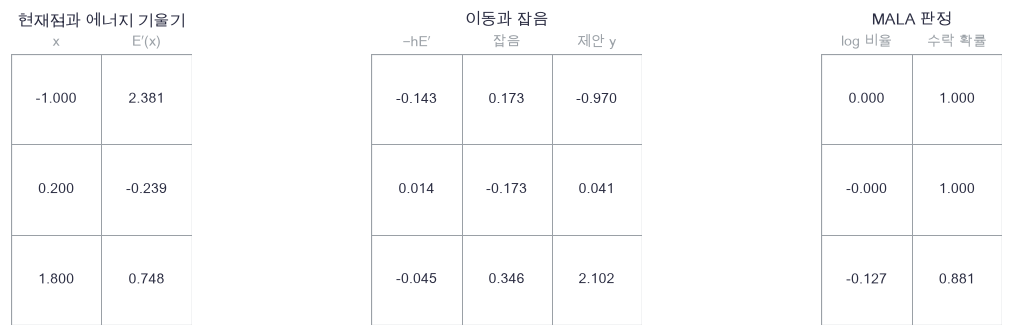

In [28]:
plot_langevin_proposal(proposal_states,proposal_parts,proposal_terms)

🔍 **확인** · drift와 잡음은 서로 다른 항입니다. 제안이 낮은 에너지로 가더라도 q의 역방향/정방향 비를 생략하면 MALA의 수락 확률이 아닙니다. 다음 검사는 log 공간의 detailed balance를 점마다 대조합니다.

In [29]:
def log_proposal(destination,origin,theta,step):
    """Langevin 제안 q(y|x)=N(x−hE′(x),2h)의 log density. 입력배열 → 같은 shape."""
    # 쓰는 것: energy_slope (2절)
    residual=destination-origin+step*energy_slope(origin,theta)
    return -.5*np.log(4*np.pi*step)-residual**2/(4*step)

In [30]:
def mala_step(x,noise,uniform,theta,step):
    """고정 noise/uniform의 Metropolis-adjusted Langevin 한 걸음. → 상태, accept mask."""
    # 쓰는 것: energy, energy_slope (2절) · log_proposal (4절)
    proposal=x-step*energy_slope(x,theta)+np.sqrt(2*step)*noise
    ratio=-energy(proposal,theta)+energy(x,theta)
    ratio+=log_proposal(x,proposal,theta,step)-log_proposal(proposal,x,theta,step)
    accepted=np.log(uniform)<np.minimum(0.,ratio)
    return np.where(accepted,proposal,x),accepted

In [31]:
def run_chains(theta,step,method,seed,draws=2400,burn=400):
    """네 초기값의 ULA/MALA chain을 실행합니다. → 보관표본:(draws,4), 전체경로, 수락률."""
    # 쓰는 것: energy_slope (2절) · mala_step (4절)
    rng=np.random.default_rng(seed)
    x=np.array([-2.,-1.,1.,2.])
    trajectory=[]
    accepts=[]
    for iteration in range(draws+burn):
        noise=rng.normal(size=4)
        uniform=rng.uniform(np.finfo(float).tiny,1.,size=4)
        if method=='MALA':
            x,accepted=mala_step(x,noise,uniform,theta,step)
        else:
            x=x-step*energy_slope(x,theta)+np.sqrt(2*step)*noise
            accepted=np.ones(4,dtype=bool)
        assert np.all(np.isfinite(x)), 'chain 상태가 유한해야 합니다'
        trajectory.append(x.copy())
        accepts.append(accepted)
    path=np.asarray(trajectory)
    return path[burn:],path,float(np.mean(accepts[burn:]))

In [32]:
# 쓰는 것: proposal_x,proposal_y,proposal_h,proposal_noise,proposal_ratio (4절 그림) · learned_theta (3절) · energy (2절)
forward=-energy(proposal_x,learned_theta)+log_proposal(proposal_y,proposal_x,learned_theta,proposal_h)+np.minimum(0.,proposal_ratio)
reverse=-energy(proposal_y,learned_theta)+log_proposal(proposal_x,proposal_y,learned_theta,proposal_h)+np.minimum(0.,-proposal_ratio)
np.testing.assert_allclose(forward,reverse,atol=1e-12)  # 검산: Z가 소거된 log detailed balance
stepped,accepted=mala_step(proposal_x,proposal_noise,np.full(3,1e-12),learned_theta,proposal_h)
np.testing.assert_allclose(stepped[accepted],proposal_y[accepted])  # 검산: 수락점은 실제 제안
rejected_state,rejected=mala_step(np.array([0.]),np.array([10.]),np.array([.99]),learned_theta,.1)
assert not rejected[0], '아주 먼 제안은 이 입력에서 거절되어야 합니다'
np.testing.assert_array_equal(rejected_state,[0.])  # 검산: 거절을 건너뛰지 않고 이전 상태 보존
for step in [.1,.5,1.]:
    variance=2*step/(1-(1-step)**2)
    np.testing.assert_allclose(variance,1/(1-step/2))  # 검산: Gaussian ULA 정상 분산 식
print('수락 비율·거절 상태·Gaussian 이산화 편향 검산 통과')

수락 비율·거절 상태·Gaussian 이산화 편향 검산 통과


### ✏️ 연습 4 · 양방향 제안 확률

log 목표값과 log 제안확률로 log 수락 비율을 완성하세요.

In [33]:
def exercise_ratio(logp_x,logp_y,logq_forward,logq_reverse):
    """양방향 제안 확률의 핵심 계산입니다."""
    ### 구현할 내용: log 목표값과 log 제안확률로 log 수락 비율을 완성하세요.
    raise NotImplementedError
    return ratio

In [34]:
def check_ratio(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    assert np.isclose(candidate(-2.,-1.,-.5,-1.),.5), '목표차1과 제안차-.5를 더해야 합니다'
    print("연습 4 통과")

run_check(check_ratio,exercise_ratio,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_ratio: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
ratio=logp_y-logp_x+logq_reverse-logq_forward
```

</details>

## 🔑 5. chain의 길이와 독립 표본 수를 구별합니다

**이 절에서 가져갈 것:** 밀도·모형 기대값·chain별 차이와 의존성을 함께 보아 샘플링 오차를 읽습니다.

과일 측정값이 한 봉우리 근처에서 오래 머물면 100번 기록해도 독립 관측 100개와 같지 않습니다. 연속 표본을 길이 b의 block으로 묶은 평균 $\bar x_k$에서

$$\widehat{SE}_{block}=\operatorname{SD}(\bar x_1,\ldots,\bar x_B)/\sqrt B$$

를 계산합니다. block이 충분히 길고 정상 상태에 가까워야 유용한 근사입니다. 그 자체가 수렴 증명이나 정확한 신뢰구간은 아닙니다.

**고정 진단:** θ는 동결합니다. ULA(h=.01,.06)와 MALA(h=.06), 초기값(−2,−1,1,2), seed315, burn-in400·보관2,400회, block100입니다. 세 방법은 같은 잡음·균등난수 계획을 사용하지만 경로는 달라집니다. 네 chain의 값을 전부 보고합니다.

> **용어** · **burn-in**은 초기 구간을 분석에서 제외하는 선택입니다. **혼합(mixing)**은 chain이 여러 영역 사이를 충분히 오가는 성질입니다. **자기상관**은 가까운 시각의 표본끼리 닮는 의존성입니다.
>
> **코드** · `reshape(B,b,C).mean(axis=1)`은 chain 축 C를 유지하고 연속 b개 시각만 평균냅니다. histogram의 분모는 화면 안 개수가 아니라 보관 표본 전체입니다.

In [35]:
block_example=np.array([[-1.,-1.1,-.9,-1.],[-.8,-.7,-.9,-.8],[.5,.8,.7,.6],[1.,.9,1.1,1.]])
block_averages=block_example.mean(axis=1)

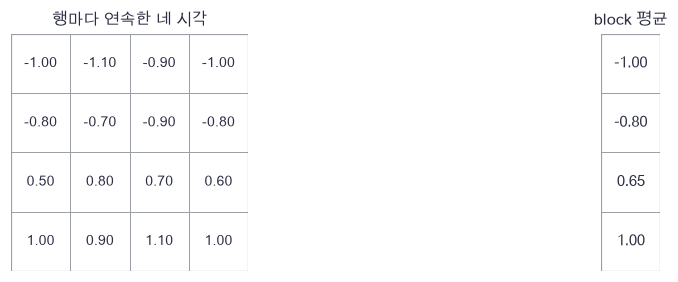

In [36]:
plot_dependent_blocks(block_example,block_averages)

🔍 **확인** · 가까운 네 시각은 서로 닮습니다. 개별 값의 SD를 전체 개수의 제곱근으로 나눈 값과 block 평균의 SE를 구분해야 합니다. block 길이에 따라서도 근사가 달라집니다.

In [37]:
def batch_mean_se(values,batch_length=100):
    """긴 연속 block 평균의 SD로 평균의 SE를 근사합니다. (T,C) → (C,)."""
    count=len(values)//batch_length
    trimmed=values[:count*batch_length]
    averages=trimmed.reshape(count,batch_length,values.shape[1]).mean(axis=1)
    return averages.std(axis=0,ddof=1)/np.sqrt(count)

In [38]:
# 쓰는 것: learned_theta (3절) · run_chains (4절)
sampling_settings=[('ULA',.01),('ULA',.06),('MALA',.06)]
sampling_labels=['ULA h=.01','ULA h=.06','MALA h=.06']
frozen_theta=learned_theta.copy()
chain_samples=[]
chain_paths=[]
chain_summary=[]
for method,step in sampling_settings:
    samples,path,acceptance=run_chains(learned_theta,step,method,315)
    chain_samples.append(samples)
    chain_paths.append(path)
    chain_summary.append([acceptance,samples.mean(),samples.mean(axis=0).std(ddof=1),batch_mean_se(samples).mean()])
    print(method,step,'· 각 chain 평균:',samples.mean(axis=0),'· block SE:',batch_mean_se(samples))
np.testing.assert_array_equal(learned_theta,frozen_theta)  # 검산: 생성 중 모델 파라미터 동결

ULA 0.01 · 각 chain 평균: [-0.81437787 -0.24677351  0.49359314 -0.36772379] · block SE: [0.27050074 0.32186061 0.29486729 0.32458   ]
ULA 0.06 · 각 chain 평균: [-0.99952612 -0.52204133 -0.82680769 -0.75431472] · block SE: [0.21619295 0.25141727 0.23730262 0.26270398]
MALA 0.06 · 각 chain 평균: [-0.85904262 -0.98610403 -0.71457639 -0.66007096] · block SE: [0.25449368 0.22241226 0.26900749 0.27335816]


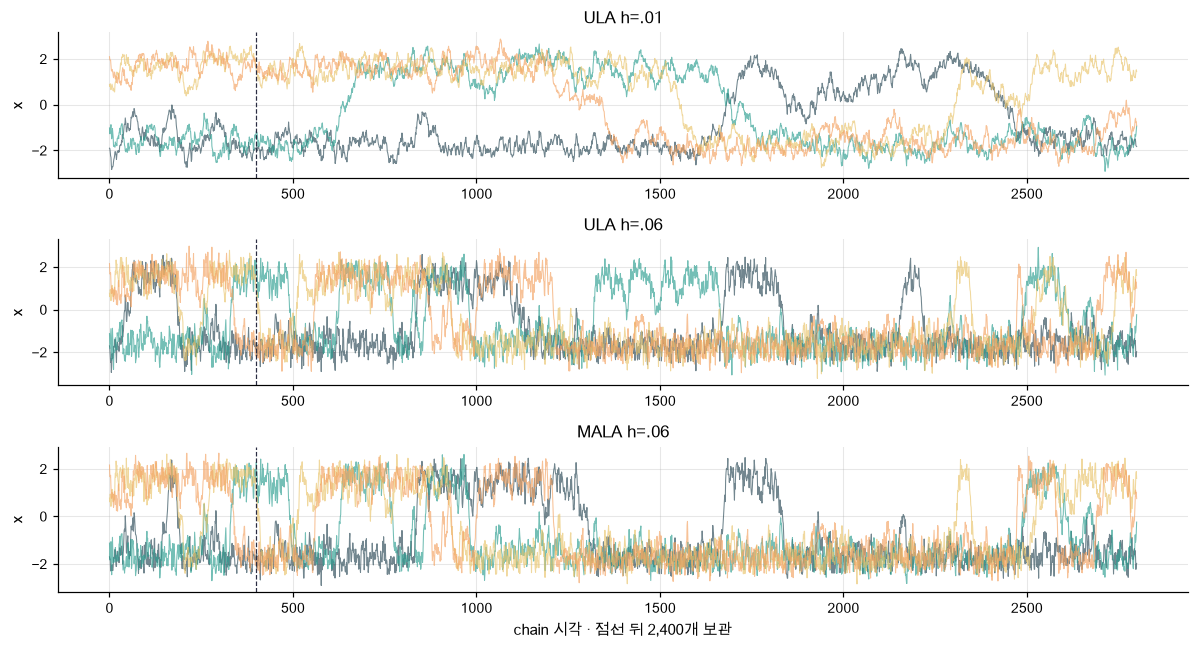

In [39]:
plot_chains(chain_paths,sampling_labels)

🔍 **확인** · 점선 이전이 제외 구간입니다. 짧은 스텝의 chain이 한 봉우리에 오래 머무를 수 있습니다. MALA의 수락 보정은 정상 분포의 정확성과 관련되며, 유한 경로가 이미 충분히 섞였다는 보장은 아닙니다.

In [40]:
# 쓰는 것: chain_samples,chain_summary,sampling_labels (5절) · learned_density,learned_theta,grid,train (3절) · energy_features,grid_distribution (2절)
hist_edges=np.linspace(-4,4,41)
hist_centers=(hist_edges[:-1]+hist_edges[1:])/2
histograms=[]
exact_negative=grid_distribution(grid,learned_theta)[2]@energy_features(grid)
positive=energy_features(train).mean(axis=0)
for samples in chain_samples:
    histogram=np.histogram(samples.ravel(),bins=hist_edges)[0]/(samples.size*np.diff(hist_edges))
    histograms.append(histogram)
    estimated_negative=np.array([samples.mean(),np.mean(samples**2)])
    print('정확 격자 phase / chain phase:',exact_negative,estimated_negative)
    print('격자 기울기 / chain 근사 기울기:',positive-exact_negative,positive-estimated_negative)
    print('독립 가정 SE / block SE:',samples.std(axis=0,ddof=1)/np.sqrt(len(samples)),batch_mean_se(samples))
    print('그림 범위 밖 비율:',np.mean(np.abs(samples)>4))

정확 격자 phase / chain phase: [-0.85502497  2.72958388] [-0.23382051  2.58297068]
격자 기울기 / chain 근사 기울기: [ 0.0000000e+00 -4.4408921e-16] [-0.62120446  0.14661321]
독립 가정 SE / block SE: [0.02779924 0.03289063 0.03025382 0.03281922] [0.27050074 0.32186061 0.29486729 0.32458   ]
그림 범위 밖 비율: 0.0
정확 격자 phase / chain phase: [-0.85502497  2.72958388] [-0.77567247  2.59011485]
격자 기울기 / chain 근사 기울기: [ 0.0000000e+00 -4.4408921e-16] [-0.0793525   0.13946904]
독립 가정 SE / block SE: [0.02623536 0.03006266 0.02816459 0.02968459] [0.21619295 0.25141727 0.23730262 0.26270398]
그림 범위 밖 비율: 0.0
정확 격자 phase / chain phase: [-0.85502497  2.72958388] [-0.8049485   2.67331248]
격자 기울기 / chain 근사 기울기: [ 0.0000000e+00 -4.4408921e-16] [-0.05007647  0.0562714 ]
독립 가정 SE / block SE: [0.02854343 0.02647742 0.02977701 0.03078181] [0.25449368 0.22241226 0.26900749 0.27335816]
그림 범위 밖 비율: 0.0


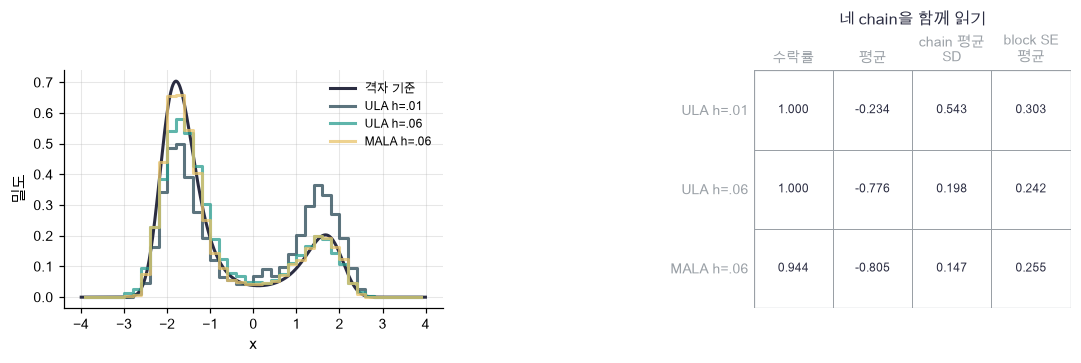

In [41]:
plot_chain_density(grid,learned_density,hist_centers,histograms,sampling_labels,np.asarray(chain_summary))

🔍 **확인** · 이 그림은 짧은 chain의 결과까지 모두 남깁니다. ULA는 이산화 편향과 유한 chain 오차가 함께 있고, MALA도 유한 chain 오차가 남습니다. 격자 기준 역시 연속 적분의 수치 근사입니다. 앞 학습에서는 정확한 격자 negative phase를 썼지만 이를 chain 평균으로 대체하면 지금 본 오차가 갱신에 들어갑니다. 이 작은 실험을 고차원 EBM의 학습 품질 보장으로 읽지 않습니다.

### ✏️ 연습 5 · block 평균의 표준오차

독립에 가까운 block 평균들의 표본 SD를 block 수의 제곱근으로 나누세요.

In [42]:
def exercise_block_se(means):
    """block 평균의 표준오차의 핵심 계산입니다."""
    ### 구현할 내용: 독립에 가까운 block 평균들의 표본 SD를 block 수의 제곱근으로 나누세요.
    raise NotImplementedError
    return se

In [43]:
def check_block_se(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    assert np.isclose(candidate(np.array([1.,3.])),1.), '두 block 평균의 SE는1입니다'
    print("연습 5 통과")

run_check(check_block_se,exercise_block_se,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_block_se: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
se=means.std(ddof=1)/np.sqrt(len(means))
```

</details>

## ✏️ 전체 연결 연습 A–D

정규화·밀도 단위·시간 이산화·거절 처리를 따로 확인합니다.

### ✏️ 연습 A · logZ의 미분 부호

모형 특징 평균에서 logZ의 θ 미분을 쓰세요.

In [44]:
def exercise_logz_gradient(model_mean):
    """logZ의 미분 부호의 핵심 계산입니다."""
    ### 구현할 내용: 모형 특징 평균에서 logZ의 θ 미분을 쓰세요.
    raise NotImplementedError
    return gradient

In [45]:
def check_logz_gradient(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    np.testing.assert_allclose(candidate(np.array([1.,2.])),[-1.,-2.])  # 검산: 음의 모형 기대값
    print("연습 A 통과")

run_check(check_logz_gradient,exercise_logz_gradient,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_logz_gradient: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
gradient=-model_mean
```

</details>

### ✏️ 연습 B · 밀도에서 격자 질량으로

균일 격자 폭 width를 곱하세요.

In [46]:
def exercise_mass(density,width):
    """밀도에서 격자 질량으로의 핵심 계산입니다."""
    ### 구현할 내용: 균일 격자 폭 width를 곱하세요.
    raise NotImplementedError
    return mass

In [47]:
def check_mass(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    np.testing.assert_allclose(candidate(np.array([2.,3.]),.2),[.4,.6])  # 검산: 밀도 곱하기 폭
    print("연습 B 통과")

run_check(check_mass,exercise_mass,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_mass: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
mass=density*width
```

</details>

### ✏️ 연습 C · Gaussian ULA의 정상 분산

0<h<2에서 정상 분산을 쓰세요.

In [48]:
def exercise_ula_variance(h):
    """Gaussian ULA의 정상 분산의 핵심 계산입니다."""
    ### 구현할 내용: 0<h<2에서 정상 분산을 쓰세요.
    raise NotImplementedError
    return variance

In [49]:
def check_ula_variance(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    assert np.isclose(candidate(1.),2.), 'h=1이면 목표분산1이 아니라2입니다'
    assert np.isclose(candidate(.5),4/3), 'h=.5이면4/3입니다'
    print("연습 C 통과")

run_check(check_ula_variance,exercise_ula_variance,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_ula_variance: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
variance=1/(1-h/2)
```

</details>

### ✏️ 연습 D · 거절도 다음 표본으로 기록

수락 mask가 참일 때만 제안으로 바꾸세요.

In [50]:
def exercise_reject(old,proposal,accepted):
    """거절도 다음 표본으로 기록의 핵심 계산입니다."""
    ### 구현할 내용: 수락 mask가 참일 때만 제안으로 바꾸세요.
    raise NotImplementedError
    return state

In [51]:
def check_reject(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    np.testing.assert_array_equal(candidate(np.array([1.,2.]),np.array([3.,4.]),np.array([True,False])),[3.,2.])  # 검산: 거절 위치는 그대로
    print("연습 D 통과")

run_check(check_reject,exercise_reject,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_reject: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
state=np.where(accepted,proposal,old)
```

</details>

### ✏️ 준비도 질문 · 네 가지를 따로 확인합니다

- **설명:** 에너지를 상수만큼 옮겨도 확률이 같은 이유와 Z 없이 score를 계산하는 이유를 설명할 수 있나요?
- **수식:** logZ의 미분과 두 phase의 차이, MALA의 양방향 제안 비율을 다시 유도할 수 있나요?
- **구현:** 안정적인 격자 정규화·전체 θ/입력 미분·동결 모델 생성·거절 상태 보존을 재구성할 수 있나요?
- **변형 검산:** 격자 폭/영역과 chain step/burn-in/block 길이를 바꾸어 수치 적분 오차·편향·의존성을 구분할 수 있나요?

### 📎 다음 연결

32·33번의 score는 −E′와 이어지지만, 직접 score 신경망을 학습하면 Z를 구하지 않아도 됩니다. 36번에서는 정상 분포로 섞이는 chain 대신 시간에 따른 velocity를 학습하여 ODE로 분포를 운반합니다. 생성 결과는 37번의 고정 평가 원칙으로 읽습니다.